# Introduction

In part 1 of this assessment, you will complete several requested SQL queries in order to extract data, analyze, and provide insights from a single provided SQL database. You will also visualize the key results of 3 of these queries. There are also several 'Reflection' questions that ask you to write out a text based answer in the provided markdown cell. Following the guided question and answer section, in part 2 you will explore a second dataset on your own using SQL in order to conduct a preliminary analysis. You will be asked to produce a very short slide presentation highlighting the work you did for this second section.

## Objectives
You will be able to:
- Interpret "word problems" and translate them into SQL queries
- Decide and perform whichever type of JOIN is best for retrieving desired data
- Use GROUP BY statements to apply aggregate functions like COUNT, MAX, MIN, and SUM
- Use the HAVING clause to compare different aggregates
- Write subqueries to decompose complex queries
- Visualize data using matplotlib, seaborn, or pandas
- Choose the correct chart type based on the given data


## Part 1: Guided SQL Queries

### Your Task: Querying a Customer Database

![toy car picture](images/toycars.jpg)


### Business Understanding
Your employer sells wholesale miniature models of products such as classic cars, motorcycles, and planes. They want you to pull several reports on different segments of their past customers, in order to better understand past sales as well as determine which customers will receive promotional material. They are also interested in investigating which products have performed the best, as well as having several smaller asks.

In addition to providing the requested data from the SQL database you have also been asked to create some basic visuals to display some of the more insightful information. It is up to your discretion to choose the correct plot/chart type for the data in question. **Questions that want you to visualize the results will be explicitly marked**.

### Data Understanding
You may remember this database from a previous lab. As a refresher, here's the ERD diagram for this database:

![ERD picture](images/ERD.png)

The queries you are asked to write will become more complex over the course of the lab.



### Getting Started
For this assessment you are expected to make use of both sqlite3 and the Pandas libraries in order to write, execute, and return SQL queries as a Pandas DataFrame. Assign each returned answer as its own explicit variable.

For the visualization piece you are expected to utilize either Pandas, Seaborn, or Matplotlib to create your visuals. Make sure you are providing verbose labels and titles according to the data you are being asked to visualize. Do not worry too much about choosing a 'style' or 'context' instead focus on conveying the requested information correctly.

### Step 1: Connect to Data

In the cell below
- Import the necessary libraries
- Establish a connection to the database data.sqlite

In [1]:
# Imports
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create connection to database
conn = sqlite3.connect('data.sqlite')


### Step 2: Limited Edition California Product
The California sales rep team is interested in running promotional material for a new limited edition model they are releasing based on the famous San Francisco Cable Cars. This product will only be available to customer stores based in California and given its high price value they want to first target promotional material to existing California customers with a high credit limit. Upon communicating with the accounting department, a credit limit of over 25,000 is considered to be high. 

Execute a SQl query that returns which customers the sales rep team wants to market to first.
*Hint*: Make sure creditLimit is numeric.

In [2]:
# California customers with high credit limits
california_high_credit = pd.read_sql_query("""
SELECT
    customerNumber,
    customerName,
    contactFirstName,
    contactLastName,
    phone,
    city,
    state,
    country,
    CAST(creditLimit AS REAL) AS creditLimit
FROM customers
WHERE state = 'CA'
  AND CAST(creditLimit AS REAL) > 25000
ORDER BY creditLimit DESC;
""", conn)

california_high_credit


,customerNumber,customerName,contactFirstName,contactLastName,phone,city,state,country,creditLimit
0,124,Mini Gifts Distributors Ltd.,Susan,Nelson,4155551450,San Rafael,CA,USA,210500.0
1,239,Collectable Mini Designs Co.,Valarie,Thompson,7605558146,San Diego,CA,USA,105000.0
2,321,Corporate Gift Ideas Co.,Julie,Brown,6505551386,San Francisco,CA,USA,105000.0
3,205,Toys4GrownUps.com,Julie,Young,6265557265,Pasadena,CA,USA,90700.0
4,161,Technics Stores Inc.,Juri,Hashimoto,6505556809,Burlingame,CA,USA,84600.0
5,450,The Sharp Gifts Warehouse,Sue,Frick,4085553659,San Jose,CA,USA,77600.0
6,129,Mini Wheels Co.,Julie,Murphy,6505555787,San Francisco,CA,USA,64600.0
7,487,Signal Collectibles Ltd.,Sue,Taylor,4155554312,Brisbane,CA,USA,60300.0
8,347,"Men 'R' US Retailers, Ltd.",Brian,Chandler,2155554369,Los Angeles,CA,USA,57700.0
9,475,West Coast Collectables Co.,Steve,Thompson,3105553722,Burbank,CA,USA,55400.0


### Step 3: International Collectable Campaign

The international sales rep team has reached out to you to help them identify partners for a 'Collectable' marketing campaign that highlights the potential collectors value in purchasing these model kits. They want to try and promote a 'collect them all' mentality. The team had a great idea to partner with any of their international customers (non-US) who have "Collect" in their name as a tie in to the larger theme.

Execute a SQL that returns the customers in question.

In [3]:
# Non-US customers whose names contain the substring "Collect"
international_collectors = pd.read_sql_query("""
SELECT
    customerNumber,
    customerName,
    contactFirstName,
    contactLastName,
    country
FROM customers
WHERE country <> 'USA'
  AND customerName LIKE '%Collect%'
ORDER BY country, customerName;
""", conn)

international_collectors


,customerNumber,customerName,contactFirstName,contactLastName,country
0,471,"Australian Collectables, Ltd",Sean,Clenahan,Australia
1,114,"Australian Collectors, Co.",Peter,Ferguson,Australia
2,382,Salzburg Collectables,Georg,Pipps,Austria
3,260,"Royal Canadian Collectables, Ltd.",Elizabeth,Lincoln,Canada
4,227,Heintze Collectables,Palle,Ibsen,Denmark
5,353,Reims Collectables,Paul,Henriot,France
6,415,"Bavarian Collectables Imports, Co.",Michael,Donnermeyer,Germany
7,409,Stuttgart Collectable Exchange,Rita,Müller,Germany
8,211,"King Kong Collectables, Co.",Mike,Gao,Hong Kong
9,189,"Clover Collections, Co.",Dean,Cassidy,Ireland


## Reflection Question

The `WHERE` clause applies two filters at the same time. `country <> 'USA'` removes customers based in the United States, while `customerName LIKE '%Collect%'` keeps names that contain the text **Collect** anywhere in the name. The percent signs are wildcards, so the match works for names such as *Collectables*, *Collectors*, or *Collectable*. Because the two conditions are joined with `AND`, a customer is returned only when **both** requirements are true: the customer is international and the company name contains the requested substring.


### Step 4: USA Credit and Inventory Policy - Visual Required
The USA based product team is planning to adjust its credit policies and inventory allocation strategy based on the average credit limit of its customers. They would like to target this strategy at a state level with several goals in mind. 
1. Optimize inventory distribution:
    - States with higher average credit limits might be able to place larger orders, justifying priority in inventory allocation.
    - This could help ensure that states with more purchasing power always have products in stock.
2. Tailor credit policies:
    - Adjust credit limits for new customers based on the state average.
    - Identify states where they might be too conservative or too liberal with credit limits.
3. Target marketing and sales efforts:
    - Focus promotional campaigns on states with higher credit limits, potentially leading to larger orders.
    - Develop strategies to increase sales in states with lower average credit limits.

Execute a SQl query that returns the information required to address this ask.

In [4]:
# Average customer credit limit by US state
state_credit_summary = pd.read_sql_query("""
SELECT
    state,
    COUNT(*) AS customer_count,
    ROUND(AVG(CAST(creditLimit AS REAL)), 2) AS avg_credit_limit
FROM customers
WHERE country = 'USA'
  AND state IS NOT NULL
  AND TRIM(state) <> ''
GROUP BY state
ORDER BY avg_credit_limit DESC;
""", conn)

state_credit_summary


,state,customer_count,avg_credit_limit
0,NH,1,114200.00
1,NY,6,89966.67
2,PA,3,84766.67
3,CA,11,83854.55
4,NV,1,71800.00
5,MA,9,70755.56
6,CT,4,57350.00
7,NJ,1,43000.00


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

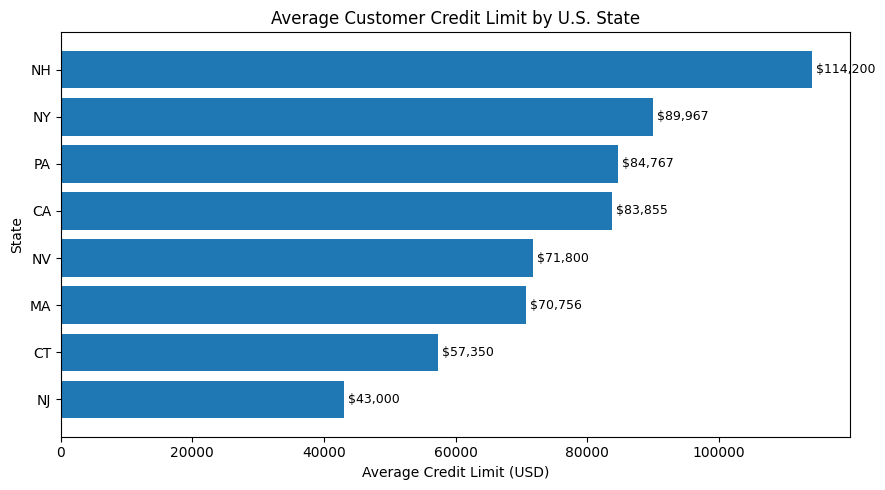

In [5]:
# Visual: average credit limit by state
plot_credit = state_credit_summary.sort_values('avg_credit_limit', ascending=True)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_credit['state'], plot_credit['avg_credit_limit'])
ax.set_title('Average Customer Credit Limit by U.S. State')
ax.set_xlabel('Average Credit Limit (USD)')
ax.set_ylabel('State')
for y, value in enumerate(plot_credit['avg_credit_limit']):
    ax.text(value, y, f' ${value:,.0f}', va='center', fontsize=9)
plt.tight_layout()
plt.savefig('images/us_state_average_credit_limit.png', dpi=160, bbox_inches='tight')
plt.show()


### Step 5: Top Customers - Visual Required
The company is approaching its 10 year anniversary and wants to acknowledge and thank its top customers with personalized communication. They have asked you to determine the top 10 customers based on the total amount of payments made, making sure to return the customer name for clarity. 

Execute a SQl query that returns the information required to address this ask.


In [6]:
# Top 10 customers by total payments
top_customers = pd.read_sql_query("""
SELECT
    c.customerNumber,
    c.customerName,
    ROUND(SUM(CAST(p.amount AS REAL)), 2) AS total_payments
FROM customers AS c
JOIN payments AS p
    ON c.customerNumber = p.customerNumber
GROUP BY c.customerNumber, c.customerName
ORDER BY total_payments DESC
LIMIT 10;
""", conn)

top_customers


,customerNumber,customerName,total_payments
0,141,Euro+ Shopping Channel,715738.98
1,124,Mini Gifts Distributors Ltd.,584188.24
2,114,"Australian Collectors, Co.",180585.07
3,151,Muscle Machine Inc,177913.95
4,148,"Dragon Souveniers, Ltd.",156251.03
5,323,"Down Under Souveniers, Inc",154622.08
6,187,"AV Stores, Co.",148410.09
7,276,"Anna's Decorations, Ltd",137034.22
8,321,Corporate Gift Ideas Co.,132340.78
9,146,"Saveley & Henriot, Co.",130305.35


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

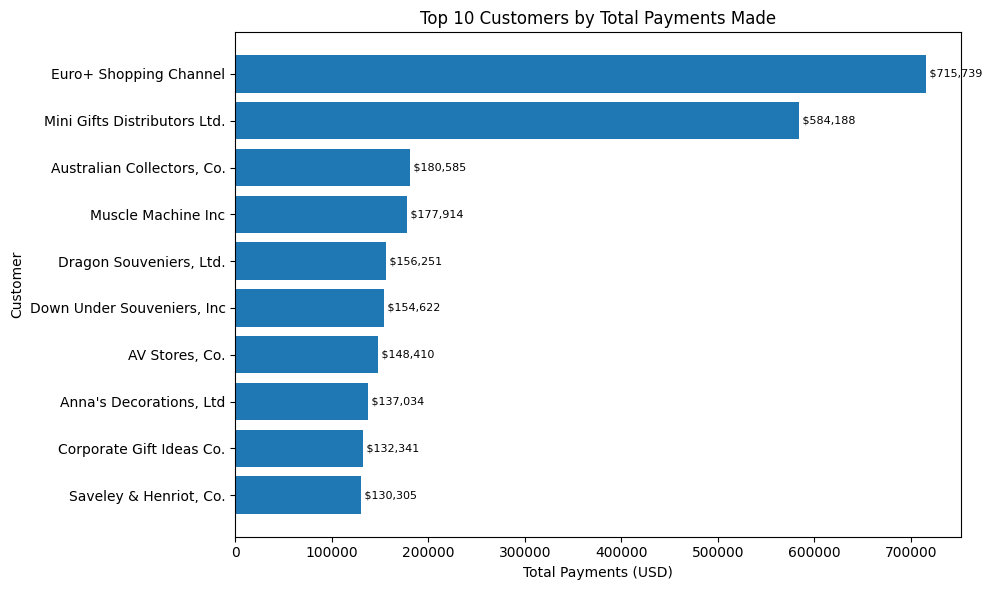

In [7]:
# Visual: top ten customers by total payments
plot_top = top_customers.sort_values('total_payments', ascending=True)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plot_top['customerName'], plot_top['total_payments'])
ax.set_title('Top 10 Customers by Total Payments Made')
ax.set_xlabel('Total Payments (USD)')
ax.set_ylabel('Customer')
for y, value in enumerate(plot_top['total_payments']):
    ax.text(value, y, f' ${value:,.0f}', va='center', fontsize=8)
plt.tight_layout()
plt.savefig('images/top_10_customers_total_payments.png', dpi=160, bbox_inches='tight')
plt.show()


### Step 6: Top Customer + Product Quantities
The product team is running an analysis on popular and common products sold to each customer in order to try and determine what new products they should be looking at to include in their catalog. This data will also be used by individual sales reps to recommend similar products to each customer next time they place an order. 

They have asked you to query information, for each customer, about any product they have purchased 10 or more units of. In addition they would like the full set of data to be sorted in ascending order by the total amount purchased.

Execute a SQl query that returns the information required to address this ask.

Hint: For this one, you'll need to make use of HAVING, GROUP BY, and ORDER BY — make sure you get the order of them correct!

In [8]:
# Customer-product combinations where at least 10 units were purchased
customer_product_quantities = pd.read_sql_query("""
SELECT
    c.customerNumber,
    c.customerName,
    p.productCode,
    p.productName,
    SUM(od.quantityOrdered) AS total_quantity_purchased
FROM customers AS c
JOIN orders AS o
    ON c.customerNumber = o.customerNumber
JOIN orderdetails AS od
    ON o.orderNumber = od.orderNumber
JOIN products AS p
    ON od.productCode = p.productCode
GROUP BY
    c.customerNumber, c.customerName,
    p.productCode, p.productName
HAVING SUM(od.quantityOrdered) >= 10
ORDER BY total_quantity_purchased ASC, c.customerName ASC, p.productName ASC;
""", conn)

customer_product_quantities


,customerNumber,customerName,productCode,productName,total_quantity_purchased
0,412,"Extreme Desk Decorations, Ltd",S24_4620,1961 Chevrolet Impala,10
1,314,Petit Auto,S18_2949,1913 Ford Model T Speedster,10
2,119,La Rochelle Gifts,S32_2509,1954 Greyhound Scenicruiser,11
3,328,Tekni Collectables Inc.,S700_1691,American Airlines: B767-300,11
4,450,The Sharp Gifts Warehouse,S24_3191,1969 Chevrolet Camaro Z28,13
...,...,...,...,...,...
2526,141,Euro+ Shopping Channel,S24_3432,2002 Chevy Corvette,174
2527,141,Euro+ Shopping Channel,S12_4473,1957 Chevy Pickup,183
2528,141,Euro+ Shopping Channel,S24_1444,1970 Dodge Coronet,197
2529,141,Euro+ Shopping Channel,S24_2840,1958 Chevy Corvette Limited Edition,245


### Step 7: Product Analysis - Visual Required

The product team is looking into the demand across its different product lines. They are conducting a comprehensive review of its product portfolio and inventory management strategies. You have been asked to query data pertaining to each different product line, that contains the total quantity ordered and the total number of products for each respective product line. By examining the number of products and total quantity ordered for each product line, the company aims to:
1. Optimize product mix:
    - Identify which product lines have the most diverse offerings (high number of products)
    - Determine which lines are most popular (high total quantity ordered)
    - Compare if lines with more products necessarily lead to more orders
2. Improve inventory management:
    - Adjust stock levels based on the popularity of each product line
    - Identify potential overstocking in lines with low order quantities
    - Ensure adequate variety in high-performing product lines
3. Adjust marketing strategy:
    - Focus promotional efforts on product lines with high potential (many products but lower order quantities)
    - Capitalize on the popularity of high-performing lines in marketing campaigns
4. Advise Product development:
    - Invest in expanding product ranges for lines with high order quantities
    - Consider phasing out or revamping product lines with low numbers of products and low order quantities

Hint: Think about how you can and might have to utilize SQL DISTINCT statement

Execute a SQl query that returns the information required to address this ask.

In [9]:
# Product-line assortment size and total order demand
product_line_summary = pd.read_sql_query("""
SELECT
    p.productLine,
    COUNT(DISTINCT p.productCode) AS number_of_products,
    SUM(od.quantityOrdered) AS total_quantity_ordered
FROM products AS p
JOIN orderdetails AS od
    ON p.productCode = od.productCode
GROUP BY p.productLine
ORDER BY total_quantity_ordered DESC;
""", conn)

product_line_summary


,productLine,number_of_products,total_quantity_ordered
0,Classic Cars,37,35582
1,Vintage Cars,24,22933
2,Motorcycles,13,12778
3,Planes,12,11872
4,Trucks and Buses,11,11001
5,Ships,9,8532
6,Trains,3,2818


Once you have the information returned in a dataframe, select an appropriate visualization to represent the relationship between total quantity ordered and the number of products in order to perform a preliminary investigation into the question of if more products lead to more orders. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

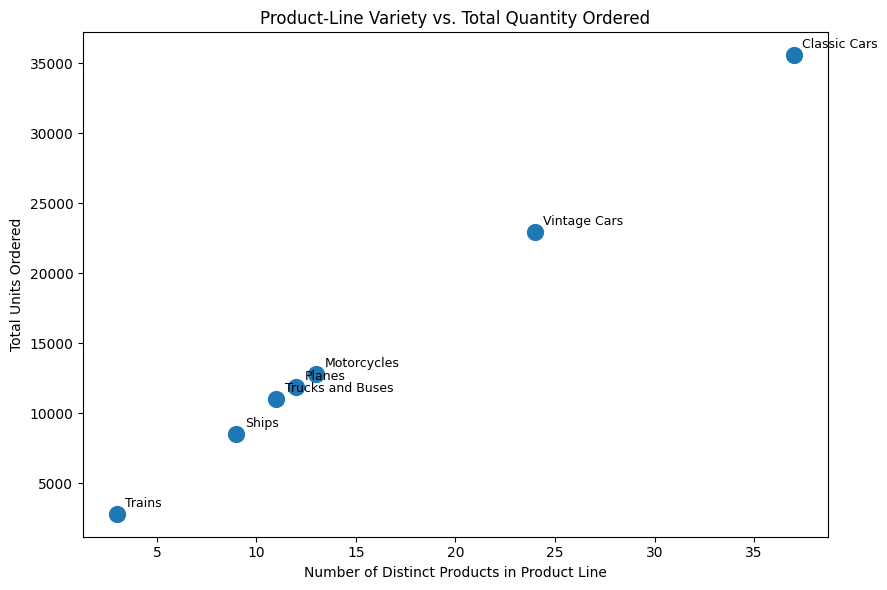

In [10]:
# Visual: relationship between assortment size and quantity ordered
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(product_line_summary['number_of_products'], product_line_summary['total_quantity_ordered'], s=130)
for _, row in product_line_summary.iterrows():
    ax.annotate(
        row['productLine'],
        (row['number_of_products'], row['total_quantity_ordered']),
        xytext=(6, 5),
        textcoords='offset points',
        fontsize=9
    )
ax.set_title('Product-Line Variety vs. Total Quantity Ordered')
ax.set_xlabel('Number of Distinct Products in Product Line')
ax.set_ylabel('Total Units Ordered')
plt.tight_layout()
plt.savefig('images/product_line_variety_vs_demand.png', dpi=160, bbox_inches='tight')
plt.show()


## Reflection Question

I used a **scatter plot** because the question is about the relationship between two numerical measures: the number of distinct products in a product line and the total quantity ordered. Each point represents one product line, so its horizontal position shows assortment size and its vertical position shows demand. This makes it easy to see whether product lines with more products generally also receive more orders and to identify any product lines that do not follow the overall pattern. In this dataset, the points show a clear positive relationship: product lines with broader assortments tend to have higher total quantities ordered, with Classic Cars and Vintage Cars standing out as the largest and highest-volume lines.


### Step 8: Remote Offices
Upper management is considering a shift to hybrid and remote work for certain locations and roles. They have tasked you with providing them data about employees who work in any office that has fewer than 5 total employees so they can better understand how to support those employees remotely when offices are shut down. 

Be sure to include information about the employees job and supervisor so management can adjust everyone to remote work properly.

Hint: Utilize a subquery to find the relevant offices

Execute a SQl query that returns the information required to address this ask.

In [11]:
# Employees in offices with fewer than five employees
remote_office_employees = pd.read_sql_query("""
SELECT
    e.employeeNumber,
    e.firstName,
    e.lastName,
    e.jobTitle,
    e.officeCode,
    o.city AS officeCity,
    e.reportsTo AS supervisorEmployeeNumber,
    s.firstName AS supervisorFirstName,
    s.lastName AS supervisorLastName
FROM employees AS e
LEFT JOIN offices AS o
    ON e.officeCode = o.officeCode
LEFT JOIN employees AS s
    ON e.reportsTo = s.employeeNumber
WHERE e.officeCode IN (
    SELECT officeCode
    FROM employees
    GROUP BY officeCode
    HAVING COUNT(*) < 5
)
ORDER BY e.officeCode, e.firstName, e.lastName;
""", conn)

remote_office_employees


,employeeNumber,firstName,lastName,jobTitle,officeCode,officeCity,supervisorEmployeeNumber,supervisorFirstName,supervisorLastName
0,1188,Julie,Firrelli,Sales Rep,2,Boston,1143,Anthony,Bow
1,1216,Steve,Patterson,Sales Rep,2,Boston,1143,Anthony,Bow
2,1286,Foon Yue,Tseng,Sales Rep,3,NYC,1143,Anthony,Bow
3,1323,George,Vanauf,Sales Rep,3,NYC,1143,Anthony,Bow
4,1621,Mami,Nishi,Sales Rep,5,Tokyo,1056,Mary,Patterson
5,1625,Yoshimi,Kato,Sales Rep,5,Tokyo,1621,Mami,Nishi
6,1611,Andy,Fixter,Sales Rep,6,Sydney,1088,William,Patterson
7,1612,Peter,Marsh,Sales Rep,6,Sydney,1088,William,Patterson
8,1619,Tom,King,Sales Rep,6,Sydney,1088,William,Patterson
9,1088,William,Patterson,Sales Manager (APAC),6,Sydney,1056,Mary,Patterson


## Reflection Question

The subquery first solves the smaller problem: **which office codes have fewer than five employees?** It groups the `employees` table by `officeCode` and uses `HAVING COUNT(*) < 5` because the filter depends on an aggregate count. The outer query then uses those office codes in a `WHERE ... IN (...)` condition to return the individual employees who work in those locations. I then join to `offices` to add the office city and self-join `employees` to obtain each employee's supervisor name. This keeps the aggregate filtering separate from the detailed employee report and avoids hard-coding office codes.


### Step 9: Close the Connection

Now that you are finished executing your queries and retrieving the required information you always want to make sure to close the connection to your database.

In [12]:
# Close the Part 1 database connection
conn.close()


### End of Guided Section
In this initial portion of the assessment, you produced several data queries and visualizations for a model company, mainly focused around its customer and product data. You wrote and engineered specific SQL queries to address pertinent questions and asks from the company. Along the way, you utilized many of the major concepts and keywords associated with SQL SELECT queries: FROM, WHERE, GROUP BY, HAVING, ORDER BY, JOIN, SUM, COUNT, and AVG.

## Part 2: Exploratory Analysis with SQL
In this open-ended exploratory section, you will analyze real-world data from the movie industry. As a data analyst, you have the freedom to investigate questions and topics that intrigue you within this dataset. The database schema and Entity-Relationship Diagram (ERD) are provided below for your reference. A general overview and instructions are also provided below.

In [13]:
# Run this cell without changes
import zipfile

zip_file_path = 'im.db.zip'
extract_to_path = './'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

# Connection
conn4 = sqlite3.connect('im.db')

# Schema
schema_df = pd.read_sql("""
SElECT * FROM sqlite_master                        
""", conn4)
schema_df

,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## The Data

![movie ERD](images/movie_data_erd.jpeg)
### Database Content:

- Source: IMDB
- Time Range: Movies released between 2010 and 2019
- Note: Exclude any movies with a start_year after 2019 as this data is not current or accurate

Available Data Categories:
- Genre
- Runtime
- Personnel (writers, directors, actors)
- Movie ratings

### Objectives:

Initial Exploration:
- Use SQL in combination with Pandas to explore the database
- Identify interesting trends, patterns, or relationships in the data

Business Question Formulation:
- Develop at least one substantial business question for deeper analysis
- Ensure the question is relevant, specific, and can be addressed with the available data

Data Cleaning Assessment:
- Identify potential data cleaning tasks necessary for your deeper analysis
- Note: You are not required to perform the cleaning, only to recognize and list the necessary tasks

Null Value Handling:
- Be aware that the dataset contains null values in certain fields
- Exclude these null values from your exploration
- Do not attempt to input or fill in missing information

### Deliverables:

You need to produce a short slide presentation (3-5 slides) that highlights the three key deliverables below. Utilize a data visualization to support the second deliverable.

1. A summary of your initial data exploration findings
    - Can be bulleted or sentence form
2. At least one well-formulated business question for further analysis
    - Should stem from a relevant trend or pattern your initial exploration identified
3. A list of potential data cleaning tasks identified during your exploration
    - This can and should include things like data normalization/standardization and null handling

Tips for Success:

Begin with broad exploratory queries to understand the data's scope and content. Then focus on honing in on interesting relationships between different data categories. Consider industry trends, audience preferences, or financial aspects when formulating your business question. Pay attention to data quality issues, inconsistencies, or limitations that might affect your analysis. Remember, the goal is to demonstrate your analytical thinking and ability to derive meaningful insights from complex datasets. Good luck with your exploration!

NOTE: You do not need to explore every aspect of this database. Find something that you think is interesting or relevant about the data and focus your exploration there.

In [14]:
# Initial exploration of the IMDb movie database
movie_scope = pd.read_sql_query("""
SELECT
    COUNT(*) AS total_movie_records,
    MIN(start_year) AS min_start_year,
    MAX(start_year) AS max_start_year,
    SUM(CASE WHEN start_year > 2019 THEN 1 ELSE 0 END) AS records_after_2019
FROM movie_basics;
""", conn4)

valid_period_quality = pd.read_sql_query("""
SELECT
    COUNT(*) AS movies_2010_2019,
    SUM(CASE WHEN runtime_minutes IS NULL THEN 1 ELSE 0 END) AS missing_runtime,
    SUM(CASE WHEN genres IS NULL THEN 1 ELSE 0 END) AS missing_genres,
    SUM(CASE WHEN runtime_minutes < 40 THEN 1 ELSE 0 END) AS runtime_under_40,
    SUM(CASE WHEN runtime_minutes > 240 THEN 1 ELSE 0 END) AS runtime_over_240
FROM movie_basics
WHERE start_year BETWEEN 2010 AND 2019;
""", conn4)

rating_scope = pd.read_sql_query("""
SELECT
    COUNT(*) AS rated_movies,
    ROUND(AVG(r.averagerating), 2) AS mean_rating,
    CAST(AVG(r.numvotes) AS INTEGER) AS mean_votes
FROM movie_basics AS b
JOIN movie_ratings AS r
    ON b.movie_id = r.movie_id
WHERE b.start_year BETWEEN 2010 AND 2019;
""", conn4)

print('Overall movie table scope:')
display(movie_scope)
print('Data-quality checks for 2010-2019:')
display(valid_period_quality)
print('Rated-movie scope for 2010-2019:')
display(rating_scope)


Overall movie table scope:


,total_movie_records,min_start_year,max_start_year,records_after_2019
0,146144,2010,2115,1063


Data-quality checks for 2010-2019:


,movies_2010_2019,missing_runtime,missing_genres,runtime_under_40,runtime_over_240
0,145081,30765,5359,5209,207


Rated-movie scope for 2010-2019:


,rated_movies,mean_rating,mean_votes
0,73856,6.33,3523


### Part 2 — Initial Exploration

The exploration is restricted to movies with `start_year` from **2010 through 2019**, as required. Missing values are excluded from analyses where the missing field is needed; no missing values are imputed.


In [15]:
# Rated movies by release year
year_summary = pd.read_sql_query("""
SELECT
    b.start_year,
    COUNT(*) AS rated_movies,
    ROUND(AVG(r.averagerating), 2) AS avg_rating,
    CAST(AVG(r.numvotes) AS INTEGER) AS avg_votes
FROM movie_basics AS b
JOIN movie_ratings AS r
    ON b.movie_id = r.movie_id
WHERE b.start_year BETWEEN 2010 AND 2019
GROUP BY b.start_year
ORDER BY b.start_year;
""", conn4)

year_summary


,start_year,rated_movies,avg_rating,avg_votes
0,2010,6792,6.26,4488
1,2011,7389,6.29,4431
2,2012,7680,6.30,4261
3,2013,7990,6.29,4460
4,2014,8371,6.32,4107
5,2015,8494,6.27,3080
6,2016,8721,6.35,3052
7,2017,8713,6.40,2513
8,2018,7526,6.42,2193
9,2019,2180,6.70,1408


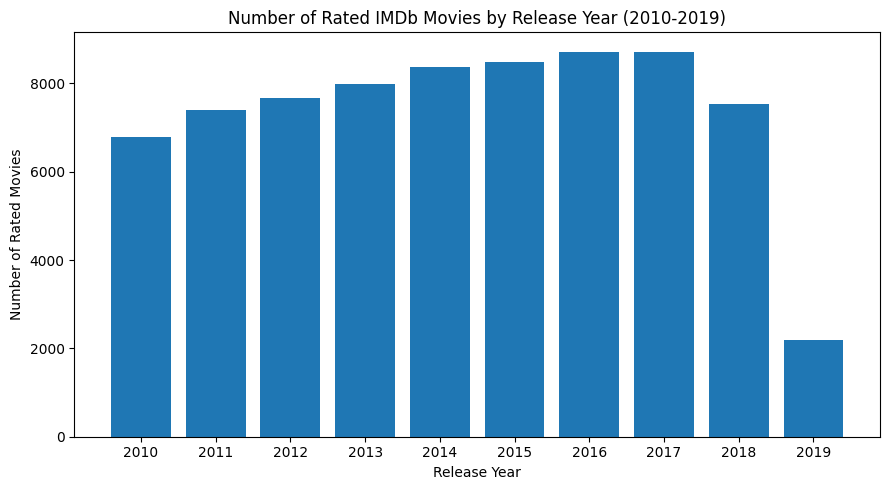

In [16]:
# Visualize the number of rated movies by year
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(year_summary['start_year'].astype(str), year_summary['rated_movies'])
ax.set_title('Number of Rated IMDb Movies by Release Year (2010-2019)')
ax.set_xlabel('Release Year')
ax.set_ylabel('Number of Rated Movies')
plt.tight_layout()
plt.savefig('images/imdb_rated_movies_by_year.png', dpi=160, bbox_inches='tight')
plt.show()


### Initial Exploration Findings

- The movie table contains **146,144 records**, including **1,063 records with a start year after 2019**. Those later records are excluded because the assessment specifies 2010-2019 as the valid analysis period.
- There are **145,081 movie records** from 2010-2019, but only **73,856** have a matching rating record. Analyses involving ratings therefore describe the rated subset, not every movie in `movie_basics`.
- Within the valid period, **30,765 movies have missing runtime** and **5,359 have missing genre information**. These nulls need to be excluded whenever those fields are required.
- Runtime also contains implausible or non-feature-length values: **5,209 records are under 40 minutes** and **207 exceed 240 minutes**. This indicates that the database mixes feature films with shorts, episodic/experimental content, or anomalous duration records.
- Average ratings are fairly stable across most years, while the number of rated movies falls sharply in 2019. The most recent year should therefore be interpreted cautiously because it appears less complete than earlier years.


### Business Question

**For IMDb-rated movies released from 2010-2019, which feature-film runtime range offers the strongest combination of audience rating and audience engagement?**

This question is useful to a studio or streaming content team because runtime is a controllable production characteristic, while average rating and vote volume provide two different signals of audience response. For this exploratory comparison, I restrict runtime to **40-240 minutes** to avoid shorts and extreme duration records identified during the initial quality review.


In [17]:
# Runtime-band analysis using only records with valid runtime and rating data
runtime_summary = pd.read_sql_query("""
SELECT
    CASE
        WHEN b.runtime_minutes < 80 THEN '40-79 min'
        WHEN b.runtime_minutes < 100 THEN '80-99 min'
        WHEN b.runtime_minutes < 120 THEN '100-119 min'
        WHEN b.runtime_minutes < 150 THEN '120-149 min'
        ELSE '150-240 min'
    END AS runtime_band,
    COUNT(*) AS movie_count,
    ROUND(AVG(r.averagerating), 2) AS avg_rating,
    CAST(AVG(r.numvotes) AS INTEGER) AS avg_votes
FROM movie_basics AS b
JOIN movie_ratings AS r
    ON b.movie_id = r.movie_id
WHERE b.start_year BETWEEN 2010 AND 2019
  AND b.runtime_minutes IS NOT NULL
  AND b.runtime_minutes BETWEEN 40 AND 240
GROUP BY runtime_band
ORDER BY CASE runtime_band
    WHEN '40-79 min' THEN 1
    WHEN '80-99 min' THEN 2
    WHEN '100-119 min' THEN 3
    WHEN '120-149 min' THEN 4
    ELSE 5
END;
""", conn4)

runtime_summary


,runtime_band,movie_count,avg_rating,avg_votes
0,40-79 min,13618,6.67,131
1,80-99 min,31181,6.12,1886
2,100-119 min,13659,6.32,7457
3,120-149 min,5960,6.44,13499
4,150-240 min,1449,6.61,11652


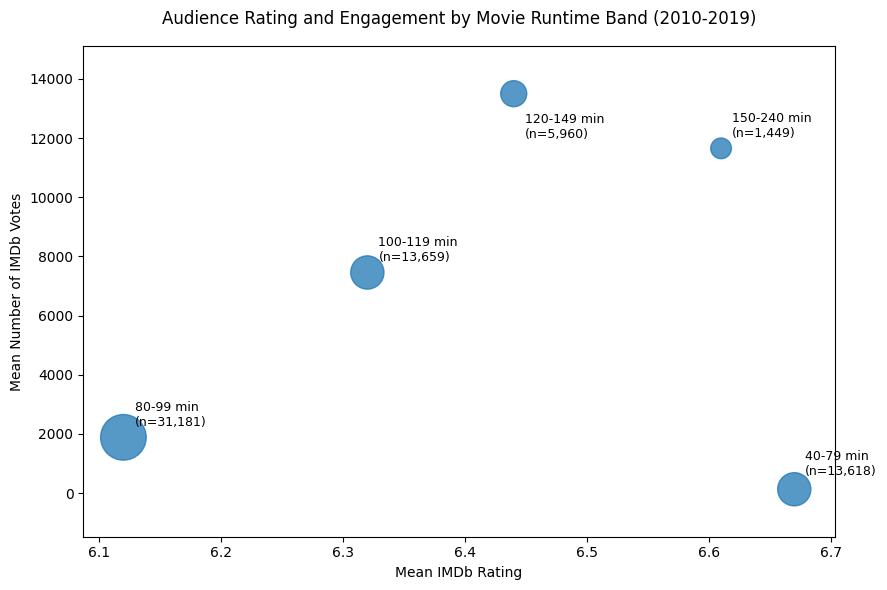

In [18]:
# Visual: rating vs. audience engagement by runtime band
fig, ax = plt.subplots(figsize=(9, 6))
sizes = 180 + (runtime_summary['movie_count'] / runtime_summary['movie_count'].max()) * 900
ax.scatter(runtime_summary['avg_rating'], runtime_summary['avg_votes'], s=sizes, alpha=0.75)
label_offsets = {
    '40-79 min': (8, 10),
    '80-99 min': (8, 8),
    '100-119 min': (8, 8),
    '120-149 min': (8, -32),
    '150-240 min': (8, 8)
}
for _, row in runtime_summary.iterrows():
    ax.annotate(
        f"{row['runtime_band']}\n(n={row['movie_count']:,})",
        (row['avg_rating'], row['avg_votes']),
        xytext=label_offsets[row['runtime_band']],
        textcoords='offset points',
        fontsize=9
    )
ax.set_title('Audience Rating and Engagement by Movie Runtime Band (2010-2019)', pad=16)
ax.set_xlabel('Mean IMDb Rating')
ax.set_ylabel('Mean Number of IMDb Votes')
ax.margins(x=0.06, y=0.12)
plt.tight_layout()
plt.savefig('images/runtime_rating_engagement.png', dpi=180, bbox_inches='tight')
plt.show()


### Interpretation of the Business Question

The runtime bands do **not** show a simple pattern in which shorter movies perform better. Movies in the **120-149 minute** band have a mean rating of about **6.44** and the **highest average vote count (about 13,499)**, making this band the strongest combination of rating and broad audience engagement in this exploratory comparison. Movies in the **150-240 minute** band have a slightly higher mean rating (**6.61**) but lower average vote volume (**about 11,652**) and a much smaller sample.

The **40-79 minute** group has the highest mean rating (**6.67**) but extremely low average vote volume (**about 131**), so the apparent rating advantage should not be interpreted as broad popularity. The large **80-99 minute** group has the lowest mean rating of the five bands (**6.12**).

For a content team, the practical signal is that **feature-length movies around two to two-and-a-half hours are associated with stronger audience engagement without sacrificing rating quality** in this dataset. This is an association, not evidence that runtime itself causes stronger performance; genre, release scale, franchise status, and audience exposure are potential confounders.


In [19]:
# Additional quality checks relevant to deeper analysis
cleaning_checks = pd.read_sql_query("""
SELECT
    COUNT(*) AS movies_2010_2019,
    SUM(CASE WHEN runtime_minutes IS NULL THEN 1 ELSE 0 END) AS missing_runtime,
    SUM(CASE WHEN genres IS NULL THEN 1 ELSE 0 END) AS missing_genres,
    SUM(CASE WHEN runtime_minutes < 40 THEN 1 ELSE 0 END) AS runtime_under_40,
    SUM(CASE WHEN runtime_minutes > 240 THEN 1 ELSE 0 END) AS runtime_over_240
FROM movie_basics
WHERE start_year BETWEEN 2010 AND 2019;
""", conn4)

cleaning_checks


,movies_2010_2019,missing_runtime,missing_genres,runtime_under_40,runtime_over_240
0,145081,30765,5359,5209,207


### Potential Data Cleaning Tasks for Deeper Analysis

1. **Enforce the valid year range:** remove records after 2019 before any analysis because the assessment explicitly identifies them as inaccurate/currently invalid.
2. **Handle nulls by exclusion, not imputation:** runtime, genre, and some personnel fields contain missing values. For any analysis using those fields, filter out null records rather than filling them with invented values.
3. **Validate runtime values:** investigate very short and extremely long runtimes. For feature-film analysis, define and document a defensible runtime range rather than treating all durations as comparable.
4. **Normalize the `genres` field:** it stores multiple comma-separated genres in a single value. A deeper genre analysis should split these into a normalized movie-to-genre structure so multi-genre movies are not treated as unique compound categories.
5. **Check duplicate keys after joins:** movie-person tables are many-to-many. Joins across `principals`, `directors`, `writers`, or `known_for` can duplicate movie rows unless the intended grain is defined first.
6. **Account for vote-count skew and recency:** `numvotes` is highly skewed and newer releases have had less time to accumulate votes. Median or log-scaled vote measures and year controls would improve robustness.
7. **Standardize text fields when needed:** names, professions, regions, and language/category labels should be checked for inconsistent casing, whitespace, aliases, or compound values before categorical comparisons.


In [20]:
# Close the Part 2 database connection
conn4.close()
